# Variables Categóricas y One-Hot Encoding

**Programa Especializado en IA · C-DAC Noida · ITEC · India 2026**

*Resuelto paso a paso — PhD (c) Luis Correa*

---
Los modelos solo entienden números. Cuando una variable es **texto** (p. ej. el nombre de un pueblo), la convertimos en columnas de 0 y 1 con *one-hot encoding*. Veremos los **dos métodos** del curso.

In [1]:
import pandas as pd

Cargamos los precios de casas en **tres pueblos**. La columna `town` es texto (categórica).

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/luiscorrea4041-ux/practicas-ia-cdac/main/data/homeprices_town.csv')
df

,town,area,price
0,monroe township,2600,550000
1,monroe township,3000,565000
2,monroe township,3200,610000
3,monroe township,3600,680000
4,monroe township,4000,725000
5,west windsor,2600,585000
6,west windsor,2800,615000
7,west windsor,3300,650000
8,west windsor,3600,710000
9,robinsville,2600,575000


## Método 1: `pd.get_dummies` (pandas)

Convierte la columna de texto en una columna 0/1 por cada pueblo.

In [3]:
dummies = pd.get_dummies(df.town)
dummies

,monroe township,robinsville,west windsor
0,True,False,False
1,True,False,False
2,True,False,False
3,True,False,False
4,True,False,False
5,False,False,True
6,False,False,True
7,False,False,True
8,False,False,True
9,False,True,False


Unimos (concatenamos) las columnas nuevas con la tabla original.

In [4]:
merged = pd.concat([df, dummies], axis='columns')
merged

,town,area,price,monroe township,robinsville,west windsor
0,monroe township,2600,550000,True,False,False
1,monroe township,3000,565000,True,False,False
2,monroe township,3200,610000,True,False,False
3,monroe township,3600,680000,True,False,False
4,monroe township,4000,725000,True,False,False
5,west windsor,2600,585000,False,False,True
6,west windsor,2800,615000,False,False,True
7,west windsor,3300,650000,False,False,True
8,west windsor,3600,710000,False,False,True
9,robinsville,2600,575000,False,True,False


Quitamos la columna de texto `town`, que ya no necesitamos.

In [5]:
final = merged.drop(['town'], axis='columns')
final

,area,price,monroe township,robinsville,west windsor
0,2600,550000,True,False,False
1,3000,565000,True,False,False
2,3200,610000,True,False,False
3,3600,680000,True,False,False
4,4000,725000,True,False,False
5,2600,585000,False,False,True
6,2800,615000,False,False,True
7,3300,650000,False,False,True
8,3600,710000,False,False,True
9,2600,575000,False,True,False


### La trampa de la variable dummy (*dummy variable trap*)

Si conoces el valor de dos pueblos, puedes **deducir** el tercero (si los dos son 0, es el tercero). Esas columnas son *multicolineales* y confunden a la regresión. Por eso **eliminamos una** columna de pueblo.

In [6]:
final = final.drop(['west windsor'], axis='columns')
final

,area,price,monroe township,robinsville
0,2600,550000,True,False
1,3000,565000,True,False
2,3200,610000,True,False
3,3600,680000,True,False
4,4000,725000,True,False
5,2600,585000,False,False
6,2800,615000,False,False
7,3300,650000,False,False
8,3600,710000,False,False
9,2600,575000,False,True


Separamos entrada (`X`) y salida (`y`).

In [7]:
X = final.drop('price', axis='columns')
X

,area,monroe township,robinsville
0,2600,True,False
1,3000,True,False
2,3200,True,False
3,3600,True,False
4,4000,True,False
5,2600,False,False
6,2800,False,False
7,3300,False,False
8,3600,False,False
9,2600,False,True


In [8]:
y = final.price
y

0     550000
1     565000
2     610000
3     680000
4     725000
5     585000
6     615000
7     650000
8     710000
9     575000
10    600000
11    620000
12    695000
Name: price, dtype: int64

Entrenamos la regresión lineal.

In [9]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 126.9 ,-40013.98,-14327.56]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['area','monroe township','robinsville']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.498e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


Medimos el **score** (R², qué tan bien ajusta) y hacemos dos predicciones.

In [10]:
model.score(X, y)

0.9573929037221873

In [11]:
model.predict([[3400, 0, 0]]) # casa de 3400 pies² en west windsor

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([681241.66845839])

In [12]:
model.predict([[2800, 0, 1]]) # casa de 2800 pies² en robinsville

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([590775.63964739])

## Método 2: `OneHotEncoder` + `ColumnTransformer` (scikit-learn)

Es la forma 'profesional'. Primero convertimos los pueblos a números con `LabelEncoder`.

In [13]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

dfle = df
dfle.town = le.fit_transform(dfle.town)
dfle

,town,area,price
0,0,2600,550000
1,0,3000,565000
2,0,3200,610000
3,0,3600,680000
4,0,4000,725000
5,2,2600,585000
6,2,2800,615000
7,2,3300,650000
8,2,3600,710000
9,1,2600,575000


Tomamos las columnas `town` y `area` como matriz de entrada, y el precio como salida.

In [14]:
X = dfle[['town','area']].values
X

array([[   0, 2600],
       [   0, 3000],
       [   0, 3200],
       [   0, 3600],
       [   0, 4000],
       [   2, 2600],
       [   2, 2800],
       [   2, 3300],
       [   2, 3600],
       [   1, 2600],
       [   1, 2900],
       [   1, 3100],
       [   1, 3600]])

In [15]:
y = dfle.price.values
y

array([550000, 565000, 610000, 680000, 725000, 585000, 615000, 650000,
       710000, 575000, 600000, 620000, 695000])

Aplicamos `OneHotEncoder` solo a la columna del pueblo (índice 0) con `ColumnTransformer`.

In [16]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
ct = ColumnTransformer([('town', OneHotEncoder(), [0])], remainder='passthrough')

In [17]:
X = ct.fit_transform(X)
X

array([[1.0e+00, 0.0e+00, 0.0e+00, 2.6e+03],
       [1.0e+00, 0.0e+00, 0.0e+00, 3.0e+03],
       [1.0e+00, 0.0e+00, 0.0e+00, 3.2e+03],
       [1.0e+00, 0.0e+00, 0.0e+00, 3.6e+03],
       [1.0e+00, 0.0e+00, 0.0e+00, 4.0e+03],
       [0.0e+00, 0.0e+00, 1.0e+00, 2.6e+03],
       [0.0e+00, 0.0e+00, 1.0e+00, 2.8e+03],
       [0.0e+00, 0.0e+00, 1.0e+00, 3.3e+03],
       [0.0e+00, 0.0e+00, 1.0e+00, 3.6e+03],
       [0.0e+00, 1.0e+00, 0.0e+00, 2.6e+03],
       [0.0e+00, 1.0e+00, 0.0e+00, 2.9e+03],
       [0.0e+00, 1.0e+00, 0.0e+00, 3.1e+03],
       [0.0e+00, 1.0e+00, 0.0e+00, 3.6e+03]])

Eliminamos la primera columna para evitar la trampa de la variable dummy.

In [18]:
X = X[:, 1:]
X

array([[0.0e+00, 0.0e+00, 2.6e+03],
       [0.0e+00, 0.0e+00, 3.0e+03],
       [0.0e+00, 0.0e+00, 3.2e+03],
       [0.0e+00, 0.0e+00, 3.6e+03],
       [0.0e+00, 0.0e+00, 4.0e+03],
       [0.0e+00, 1.0e+00, 2.6e+03],
       [0.0e+00, 1.0e+00, 2.8e+03],
       [0.0e+00, 1.0e+00, 3.3e+03],
       [0.0e+00, 1.0e+00, 3.6e+03],
       [1.0e+00, 0.0e+00, 2.6e+03],
       [1.0e+00, 0.0e+00, 2.9e+03],
       [1.0e+00, 0.0e+00, 3.1e+03],
       [1.0e+00, 0.0e+00, 3.6e+03]])

Entrenamos y predecimos igual que antes (los resultados coinciden con el Método 1).

In [19]:
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[25686.41,40013.98, 126.9 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.098e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[1572.36, 2. , 1.2 ]"


In [20]:
model.predict([[0, 1, 3400]]) # 3400 pies² en west windsor

array([681241.6684584])

In [21]:
model.predict([[1, 0, 2800]]) # 2800 pies² en robinsville

array([590775.63964739])

## Ejercicio práctico

**Enunciado (del curso):** Con el archivo `carprices.csv` (precios de venta de **3 modelos** de carro), primero graficar los puntos para ver si aplica una regresión lineal. Si aplica, construir un modelo y responder:
1. Precio de un **Mercedez Benz** de **4 años** con **45,000** millas.
2. Precio de un **BMW X5** de **7 años** con **86,000** millas.
3. El **score** (precisión) del modelo.

**Paso 1.** Cargamos los datos.

In [22]:
df_car = pd.read_csv('https://raw.githubusercontent.com/luiscorrea4041-ux/practicas-ia-cdac/main/data/carprices.csv')
df_car

,Car Model,Mileage,Sell Price($),Age(yrs)
0,BMW X5,69000,18000,6
1,BMW X5,35000,34000,3
2,BMW X5,57000,26100,5
3,BMW X5,22500,40000,2
4,BMW X5,46000,31500,4
5,Audi A5,59000,29400,5
6,Audi A5,52000,32000,5
7,Audi A5,72000,19300,6
8,Audi A5,91000,12000,8
9,Mercedez Benz C class,67000,22000,6


**Paso 2.** Graficamos millaje vs. precio, coloreando por modelo, para ver la relación lineal (a más millas, menor precio).

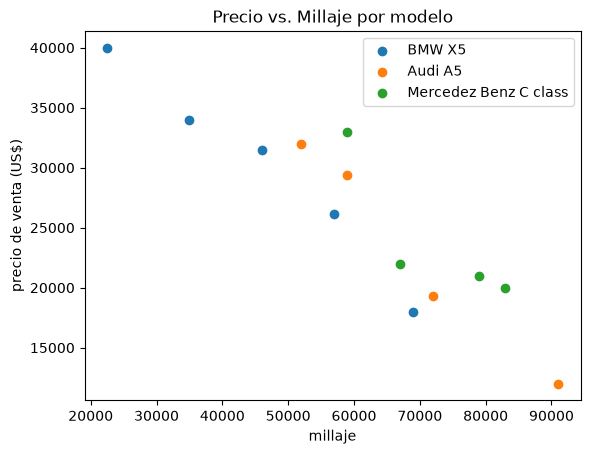

In [23]:
import matplotlib.pyplot as plt
for modelo in df_car['Car Model'].unique():
    sub = df_car[df_car['Car Model'] == modelo]
    plt.scatter(sub['Mileage'], sub['Sell Price($)'], label=modelo)
plt.xlabel('millaje'); plt.ylabel('precio de venta (US$)')
plt.legend(); plt.title('Precio vs. Millaje por modelo')
plt.show()

**Paso 3.** Codificamos el modelo de carro (texto) con one-hot usando `get_dummies` y quitamos una columna (trampa dummy).

In [24]:
dummies_car = pd.get_dummies(df_car['Car Model'])
merged_car = pd.concat([df_car, dummies_car], axis='columns')
final_car = merged_car.drop(['Car Model', 'Mercedez Benz C class'], axis='columns')
final_car

,Mileage,Sell Price($),Age(yrs),Audi A5,BMW X5
0,69000,18000,6,False,True
1,35000,34000,3,False,True
2,57000,26100,5,False,True
3,22500,40000,2,False,True
4,46000,31500,4,False,True
5,59000,29400,5,True,False
6,52000,32000,5,True,False
7,72000,19300,6,True,False
8,91000,12000,8,True,False
9,67000,22000,6,False,False


**Paso 4.** Definimos X (millaje, edad y los modelos) e y (precio), y entrenamos.

In [25]:
X_car = final_car.drop('Sell Price($)', axis='columns')
y_car = final_car['Sell Price($)']

model_car = LinearRegression()
model_car.fit(X_car, y_car)
print("Columnas de X:", list(X_car.columns))

Columnas de X: ['Mileage', 'Age(yrs)', 'Audi A5', 'BMW X5']


**Paso 5.** Respondemos las preguntas. El orden de columnas es: `Mileage, Age(yrs), Audi A5, BMW X5`.
- Mercedez = Audi 0, BMW 0.
- BMW X5 = Audi 0, BMW 1.

In [26]:
# (1) Mercedez Benz, 4 años, 45000 millas  -> Audi=0, BMW=0
p_merc = model_car.predict([[45000, 4, 0, 0]])
# (2) BMW X5, 7 años, 86000 millas         -> Audi=0, BMW=1
p_bmw = model_car.predict([[86000, 7, 0, 1]])
print(f"(1) Mercedez Benz 4 años 45000 mi -> US$ {p_merc[0]:,.2f}")
print(f"(2) BMW X5 7 años 86000 mi        -> US$ {p_bmw[0]:,.2f}")
print(f"(3) Score (R²) del modelo         -> {model_car.score(X_car, y_car):.4f}")

(1) Mercedez Benz 4 años 45000 mi -> US$ 36,991.32
(2) BMW X5 7 años 86000 mi        -> US$ 11,080.74
(3) Score (R²) del modelo         -> 0.9417


/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


**Conclusión:** el modelo logra un score (R²) alto, lo que confirma que la relación entre millaje, edad y modelo con el precio es fuertemente lineal. Las predicciones son coherentes: a más edad y millaje, menor precio.